**Pregunta 1**: Dada una lista llamada numeros que contiene una secuencia de números enteros, escribe un programa en Python que encuentre el número que aparece con mayor frecuencia en la lista y cuántas veces aparece.

```python 

numeros = [2, 3, 4, 2, 5, 2, 7, 4, 2, 8, 2, 9, 2]

```

In [1]:
numeros = [2,3,4,2,5,2,7,4,2,8,2,9,2]

frecuencias = {}

for i in range(len(numeros)):
    if numeros[i] not in frecuencias:
            frecuencias[numeros[i]] = 1
    else:
        frecuencias[numeros[i]] += 1

clave_max = max(frecuencias, key=frecuencias.get)
valor_max = frecuencias[clave_max]

print(f"Valor: {clave_max} | Frecuencia: {valor_max}")

Valor: 2 | Frecuencia: 6


**Pregunta 2**: Tienes una lista de estudiantes, donde cada estudiante es representado por un diccionario con las siguientes claves: 'nombre', 'edad' y 'promedio'. Escribe un programa en Python que encuentre el estudiante más joven con un promedio de al menos 90.

```python 

estudiantes = [
    {'nombre': 'Juan', 'edad': 18, 'promedio': 92},
    {'nombre': 'María', 'edad': 17, 'promedio': 88},
    {'nombre': 'Pedro', 'edad': 19, 'promedio': 95},
    {'nombre': 'Ana', 'edad': 17, 'promedio': 91}
]

```

In [2]:
estudiantes = [
    {'nombre': 'Juan', 'edad': 18, 'promedio': 92},
    {'nombre': 'María', 'edad': 17, 'promedio': 88},
    {'nombre': 'Pedro', 'edad': 19, 'promedio': 95},
    {'nombre': 'Ana', 'edad': 17, 'promedio': 91}
]

est_min = {'nombre': 'x', 'edad': 200, 'promedio': 0}

for estudiante in estudiantes:
    if estudiante['edad'] < est_min['edad'] and estudiante['promedio'] >= 90 :
        est_min = estudiante

print(f"Nombre: {est_min['nombre']} | Edad: {est_min['edad']} | Promedio: {est_min['promedio']}")

Nombre: Ana | Edad: 17 | Promedio: 91


**Pregunta 3**: Tienes una tupla llamada datos que contiene información de ventas de productos. Cada elemento de la tupla es un diccionario con las siguientes claves: 'producto', 'cantidad' y 'precio'. Escribe un programa en Python que calcule el monto total de ventas.

```python 

datos = (
    {'producto': 'A', 'cantidad': 10, 'precio': 25.5},
    {'producto': 'B', 'cantidad': 5, 'precio': 30.0},
    {'producto': 'C', 'cantidad': 8, 'precio': 15.75},
    {'producto': 'D', 'cantidad': 12, 'precio': 10.25}
)

```

In [3]:
datos = (
    {'producto': 'A', 'cantidad': 10, 'precio': 25.5},
    {'producto': 'B', 'cantidad': 5, 'precio': 30.0},
    {'producto': 'C', 'cantidad': 8, 'precio': 15.75},
    {'producto': 'D', 'cantidad': 12, 'precio': 10.25}
)

total = 0

for dato in datos:
     total += dato['cantidad'] * dato['precio']
    
print(f"Monto total de ventas: {total}")

Monto total de ventas: 654.0


**Pregunta 4 extra**: Programación Orientada a Objetos aplicada a Bonos Financieros

Supón que trabajas en la tesorería de un banco y necesitas crear una herramienta en Python que te permita **modelar y analizar bonos**.  
Para ello, vas a diseñar una **clase llamada `Bono`** que represente un instrumento de deuda simple con cupón fijo.

---

#### **Especificaciones de la clase**

Crea una clase `Bono` con los siguientes **atributos:**
- `valor_nominal`: Valor nominal del bono (por ejemplo, 100).
- `tasa_cupon`: Tasa de cupón anual (por ejemplo, 0.08 para 8%).
- `plazo`: Años hasta el vencimiento (por ejemplo, 5).
- `rendimiento`: Tasa de rendimiento exigida por el mercado (por ejemplo, 0.07 para 7%).

Y los siguientes **métodos:**

1. **`precio()`**  
   Calcula el **precio del bono** utilizando la fórmula clásica de valuación:

   $$
   P = \sum_{t=1}^{n} \frac{C}{(1+r)^t} + \frac{VN}{(1+r)^n}
   $$

   donde:
   - $C = VN \times \text{tasa cupón}$
   - $r = \text{rendimiento}$
   - $n = \text{plazo}$

2. **`duracion()`**  
   Calcula la **Duración de Macaulay**, medida en años:

   $$
   D = \frac{\sum_{t=1}^{n} t \cdot PV(CF_t)}{P}
   $$

   donde $PV(CF_t)$ es el valor presente del flujo de efectivo en el tiempo $t$, y $P$ es el precio calculado.

3. **`convexidad()`**  
   Calcula la **convexidad** aproximada del bono:

   $$
   Conv = \frac{\sum_{t=1}^{n} PV(CF_t) \cdot t (t+1)}{P \cdot (1+r)^2}
   $$

4. **`resumen()`**  
   Muestra en pantalla toda la información del bono, incluyendo:
   - Valor nominal  
   - Tasa de cupón  
   - Plazo  
   - Rendimiento exigido  
   - Precio calculado  
   - Duración  
   - Convexidad

---

#### **2 Ejemplo de implementación**

Crea un bono con los siguientes parámetros:
```python
mi_bono = Bono(valor_nominal=100, tasa_cupon=0.08, plazo=5, rendimiento=0.07)


In [7]:
class Bono:
    def __init__(self, valor_nominal, tasa_cupon, plazo, rendimiento):
        self.valor_nominal = valor_nominal
        self.tasa_cupon = tasa_cupon
        self.plazo = plazo
        self.rendimiento = rendimiento

    def precio(self):

        C = self.valor_nominal * self.tasa_cupon
        precio = 0

        for t in range(1, self.plazo + 1):
            precio += C / (1 + self.rendimiento) ** t

        precio += self.valor_nominal / (1 + self.rendimiento) ** self.plazo

        return precio
    

    def duracion(self):

        P = self.precio()
        C = self.valor_nominal * self.tasa_cupon
        suma = 0

        for t in range(1, self.plazo + 1):

            if t < self.plazo:
                Ft = C
            else:
                Ft = C + self.valor_nominal

            PV = Ft / (1 + self.rendimiento) ** t

            suma += t * PV

        duracion = suma / P

        return duracion
    

    def convexidad(self):

        P = self.precio()
        C = self.valor_nominal * self.tasa_cupon
        suma = 0

        for t in range(1, self.plazo + 1):

            if t < self.plazo:
                Ft = C
            else:
                Ft = C + self.valor_nominal

            PV = Ft / (1 + self.rendimiento) ** t

            suma += t * (t + 1) * PV

        Conv = suma / (P * (1 + self.rendimiento) ** 2)

        return Conv
    
    
    def resumen(self):
        print("-"*10, "Resumen del bono", "-"*10)

        print(f"Valor nominal: {self.valor_nominal}")
        print(f"Tasa cupón: {self.tasa_cupon}")
        print(f"Plazo: {self.plazo}")
        print(f"Rendimiento exigido: {self.rendimiento}")
        print(f"Precio calculado: {self.precio():.4f}")
        print(f"Duración: {self.duracion():.4f}")
        print(f"Convexidad: {self.convexidad():.4f}")

        print("-"*38)


mi_bono = Bono(valor_nominal=100, tasa_cupon=0.08, plazo=5, rendimiento=0.07)

mi_bono.resumen()



---------- Resumen del bono ----------
Valor nominal: 100
Tasa cupón: 0.08
Plazo: 5
Rendimiento exigido: 0.07
Precio calculado: 104.1002
Duración: 4.3273
Convexidad: 21.5413
--------------------------------------


**Pregunta 5**: 

Utiliza el siguiente conjunto de datos público (libre acceso):

👉 **Dataset:** [Supermarket Sales Dataset (Kaggle)](https://www.kaggle.com/datasets/faresashraf1001/supermarket-sales)  
Este dataset contiene transacciones de un supermercado, con información como:
- **Branch:** sucursal (A, B, C)
- **City:** ciudad
- **Customer type:** tipo de cliente (Member / Normal)
- **Gender:** género
- **Product line:** categoría del producto
- **Unit price:** precio unitario
- **Quantity:** cantidad vendida
- **Total:** monto total
- **Date:** fecha de la transacción
- **Payment:** método de pago
- **Rating:** calificación del cliente

Cargar y explorar la base de datos. A partir de ella, realiza el siguiente análisis paso a paso.  
Puedes usar las librerías `pandas`, `matplotlib.pyplot`, y/o `seaborn`.


#### **Distribución de ventas por sucursal**
- Calcula las ventas totales por cada sucursal (`Branch`) utilizando la columna `Total`.
- Muestra un **gráfico de barras** con las ventas de las sucursales.
- Indica el **porcentaje** que representa cada sucursal del total general.


#### **Evolución de ventas en el tiempo**
- Convierte la columna `Date` a formato de fecha (`datetime`).
- Agrupa las ventas **por mes o por día** y calcula el total de ventas.
- Genera un **gráfico de línea** que muestre cómo varía el total de ventas a lo largo del tiempo.
- Identifica si hay **tendencia, estacionalidad o variabilidad notable.**


#### **Productos más vendidos**
- Calcula la **cantidad total vendida** de cada línea de producto (`Product line`).
- Muestra los **10 productos más vendidos** en un **gráfico de barras horizontales.**
- Adicionalmente, calcula los **10 productos con mayor ingreso total (`Total`)** y compara si el ranking cambia.

#### **Segmentación de clientes**
- Agrupa por cliente (`Customer type`) y calcula el **gasto total promedio.**
- Clasifica a los clientes en niveles:  
  - Bajo: < percentil 33  
  - Medio: entre 33 y 66  
  - Alto: > percentil 66  
- Grafica cómo se distribuyen sus compras entre líneas de producto.

#### **Conclusión**
Redacta brevemente tus observaciones:
- ¿Qué sucursal genera más ventas?
- ¿Qué categoría domina el mercado?
- ¿Qué tendencias temporales observas?
- ¿Qué estrategias podrías sugerir al supermercado?

Branch
Alex     106200.3705
Cairo    106197.6720
Giza     110568.7065
Name: Sales, dtype: float64


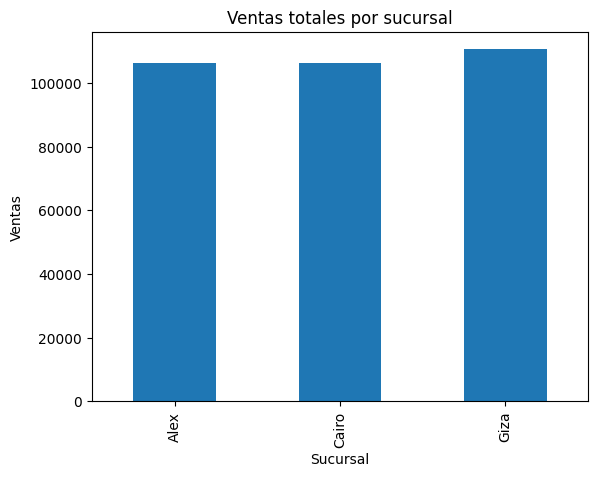

Sucursal Alex: 32.8828% del total
Sucursal Cairo: 32.8819% del total
Sucursal Giza: 34.2353% del total


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

datos = pd.read_csv("SuperMarket Analysis.csv")

# Ventas totales por sucursal
ventas_por_sucursal = datos.groupby("Branch")["Sales"].sum()
print(ventas_por_sucursal)

# Gráfico de barras
ventas_por_sucursal.plot(kind="bar")

plt.title("Ventas totales por sucursal")
plt.xlabel("Sucursal")
plt.ylabel("Ventas")
plt.show()

# Porcentaje por sucursal
ventas_totales = datos['Sales'].sum()

porcentaje = (ventas_por_sucursal / ventas_totales) * 100

for sucursal, p in porcentaje.items():
    print(f"Sucursal {sucursal}: {p:.4f}% del total")


Date
2019-01-01    4745.1810
2019-01-02    1945.5030
2019-01-03    2078.1285
2019-01-04    1623.6885
2019-01-05    3536.6835
                ...    
2019-03-26    1962.5130
2019-03-27    2902.8195
2019-03-28    2229.4020
2019-03-29    4023.2430
2019-03-30    4487.0595
Freq: D, Name: Sales, Length: 89, dtype: float64


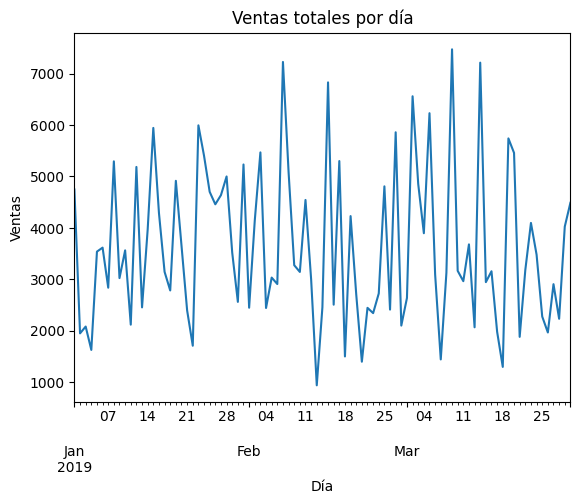

No se observa que haya una tendencia definida porque los valores suben y bajan constantemente.
Tampoco se puede observar estacionalidad evidente porque no se repite un patrón semanal o mensual.
En cambio, si se puede obsevar variabilidad porque los cambios son grandes y frecuentes.


In [34]:
# Columna Date a formato de fecha
datos['Date'] = pd.to_datetime(datos['Date'], errors='coerce')

# Ventas totales agrupadas por mes
ventas_por_dia = datos.groupby(datos["Date"].dt.to_period("D"))["Sales"].sum()
print(ventas_por_dia)

# Gráfico de línea de variaciones de ventas
ventas_por_dia.plot(kind = "line")

plt.title("Ventas totales por día")
plt.xlabel("Día")
plt.ylabel("Ventas")
plt.show()

# Identificar si hay tendencia, estacionalidad y variabilidad
print("No se observa que haya una tendencia definida porque los valores suben y bajan constantemente.\n" \
"Tampoco se puede observar estacionalidad evidente porque no se repite un patrón semanal o mensual.\n" \
"En cambio, si se puede obsevar variabilidad porque los cambios son grandes y frecuentes.")

Product line            Unit price
Home and lifestyle      34.42         12
Fashion accessories     99.82         11
Food and beverages      77.20         10
Sports and travel       95.44         10
                        76.92         10
                        76.60         10
Electronic accessories  26.26         10
Food and beverages      39.90         10
                        74.60         10
                        74.44         10
Name: Quantity, dtype: int64


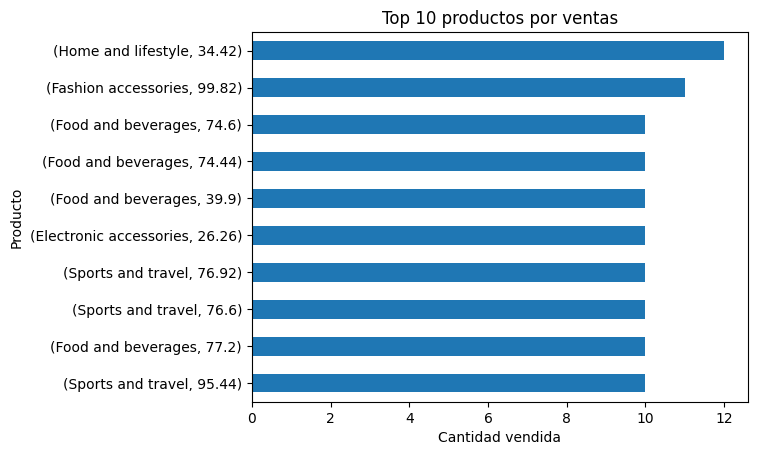

Product line         Unit price
Fashion accessories  99.82         1152.921
                     99.30         1042.650
                     98.98         1039.290
Food and beverages   98.52         1034.460
Home and lifestyle   97.50         1023.750
                     97.38         1022.490
                     97.37         1022.385
Fashion accessories  97.21         1020.705
Home and lifestyle   95.58         1003.590
Sports and travel    95.44         1002.120
Name: Sales, dtype: float64


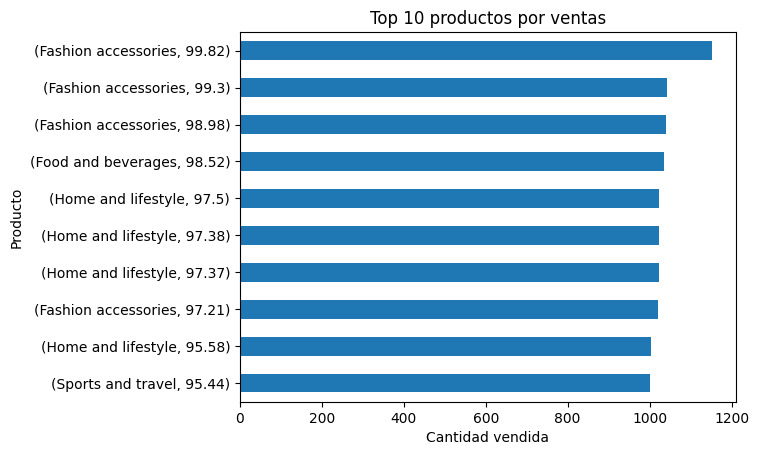

La tablas tablas si tuvieron un gran cambio entre una y otra solo se mantuvieron los que tienen un precio igual o mayor a 95.44


In [76]:
# Cantidad total vendida de cada línea de producto
ventas_por_linea = datos.groupby("Product line")["Quantity"].sum()


# 10 productos MÁS VENDIDOS en un gráfico de barras horizontales
# NO HAY CÓDIGO DE PRODUCTO ASÍ QUE TOMÉ EL PRECIO Y PRODUCT LINE COMO INDICADOR DE QUE ES EL MISMO PRODUCTO
cantidad_por_producto = datos.groupby(["Product line", "Unit price"])["Quantity"].sum()
cantidad_por_producto = cantidad_por_producto.sort_values(ascending=False)
primeros_10 = cantidad_por_producto.head(10)
print(primeros_10)

# Gráfico de línea de variaciones de ventas
primeros_10.sort_values().plot(kind="barh")

plt.title("Top 10 productos por ventas")
plt.xlabel("Cantidad vendida")
plt.ylabel("Producto")

plt.show()


# 10 productos CON MAYOR INGRESO en un gráfico de barras horizontales
# NO HAY CÓDIGO DE PRODUCTO ASÍ QUE TOMÉ EL PRECIO Y PRODUCT LINE COMO INDICADOR DE QUE ES EL MISMO PRODUCTO
ventas_por_producto = datos.groupby(["Product line", "Unit price"])["Sales"].sum()
ventas_por_producto = ventas_por_producto.sort_values(ascending=False)
primeros_10 = ventas_por_producto.head(10)
print(primeros_10)

# Gráfico de línea de variaciones de ventas
primeros_10.sort_values().plot(kind="barh")

plt.title("Top 10 productos por ventas")
plt.xlabel("Cantidad vendida")
plt.ylabel("Producto")

plt.show()

# Comparar los resultados
print("La tablas tablas si tuvieron un gran cambio entre una y otra solo se mantuvieron los que tienen un precio igual o mayor a 95.44")


Customer type
Member    Alto
Normal    Bajo
Name: Sales, dtype: str


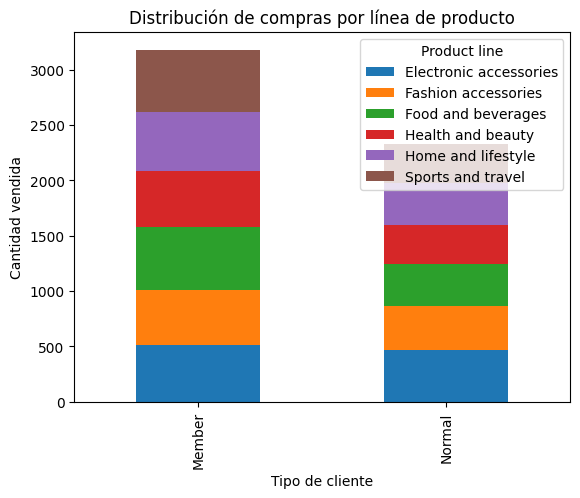

In [72]:
# Gasto total promedio
gasto_cliente = datos.groupby("Customer type")["Sales"].mean()
# print(gasto_cliente)


# Calculo de percentiles
p33 = gasto_cliente.quantile(0.33)
p66 = gasto_cliente.quantile(0.66)
# print(p33, p66)

# Clasificar cliente
def clasificar(gasto):
    if gasto < p33:
        return "Bajo"
    elif gasto < p66:
        return "Medio"
    else:
        return "Alto"

segmentos = gasto_cliente.apply(clasificar)

print(segmentos)

# Grafica cómo se distribuyen sus compras entre líneas de producto
compras = datos.groupby(["Customer type", "Product line"])["Quantity"].sum().unstack()

compras.plot(kind="bar", stacked=True)

plt.title("Distribución de compras por línea de producto")
plt.xlabel("Tipo de cliente")
plt.ylabel("Cantidad vendida")

plt.show()



In [79]:
# PARA CONTESTAR PREGUNTA DEL FINAL (CATEGORIAS MÁS VENDIDAS Y CON MÁS INGRESOS)
cantidad_por_categoria = datos.groupby(["Product line"])["Quantity"].sum()
cantidad_por_categoria = cantidad_por_categoria.sort_values(ascending=False)
primeros_10 = cantidad_por_categoria.head(10)
print(primeros_10)

ventas_por_categoria = datos.groupby(["Product line"])["Sales"].sum()
ventas_por_categoria = ventas_por_categoria.sort_values(ascending=False)
primeros_10 = ventas_por_categoria.head(10)
print(primeros_10)

Product line
Electronic accessories    971
Food and beverages        952
Sports and travel         920
Home and lifestyle        911
Fashion accessories       902
Health and beauty         854
Name: Quantity, dtype: int64
Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Sales, dtype: float64


RESPUESTAS
- ¿Qué sucursal genera más ventas?
**Giza**
- ¿Qué categoría domina el mercado?
**Food and beverages domina el mercado en términos de ingresos y Electronic accessories lidera en volumen de productos vendidos**
- ¿Qué tendencias temporales observas?
**Alta variabilidad diaria con picos periódicos, pero sin una tendencia clara de crecimiento o caída**
- ¿Qué estrategias podrías sugerir al supermercado?
**Potenciar la compra de los productos con mayores ventas dentro de la categoría de Food and beverages con promociones. Ofrecer descuentos por volumen para los productos de la categoría de Electronic accessories**


**Pregunta 6**: Supongamos que tienes un contrato de opción de venta (put) sobre una acción con un precio de ejercicio (strike) de 100. La opción tiene una fecha de vencimiento de 0.25 años, r = 9% y sigma = 29%, el precio actual de la acción es de 105. Utilizando el modelo Black-Scholes, calcula el valor de prima de la opción y la delta en este momento. Luego, escribe un programa en Python que genere un gráfico dinámico de la delta en función del precio de la acción, variando el precio de la acción desde 
80 hasta 120. Este gráfico debe proporcionar una visualización de cómo cambia la delta con respecto al precio de la acción.

Precio de la opción PUT: 2.9401
Delta de la opción: -0.2863


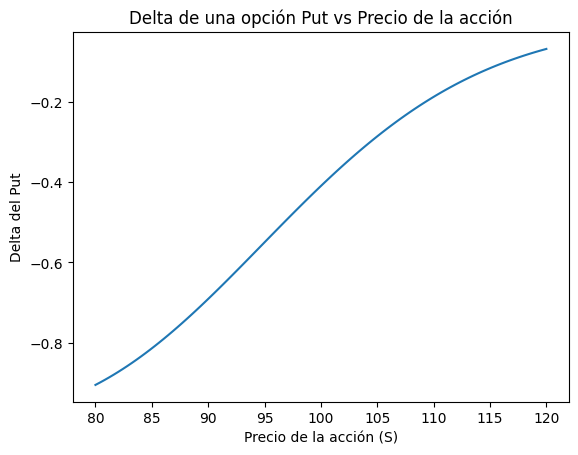

In [82]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

K = 100        
T = 0.25       
r = 0.09       
sigma = 0.29   
S = 105        

# Función Black-Scholes
def black_scholes_put(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + sigma**2/2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)

    put_price = K*np.exp(-r*T)*norm.cdf(-d2) - S*norm.cdf(-d1)
    delta_put = norm.cdf(d1) - 1

    return put_price, delta_put

# Cálculo en el precio actual
precio, delta = black_scholes_put(S, K, T, r, sigma)

print("Precio de la opción PUT:", round(precio,4))
print("Delta de la opción:", round(delta,4))

# Rango de precios de la acción
S_values = np.linspace(80,120,100)

deltas = []

for s in S_values:
    _, d = black_scholes_put(s, K, T, r, sigma)
    deltas.append(d)


# Gráfica
plt.plot(S_values, deltas)
plt.xlabel("Precio de la acción (S)")
plt.ylabel("Delta del Put")
plt.title("Delta de una opción Put vs Precio de la acción")
plt.show()

**Pregunta 7**: Realice 10,000 simulaciones de movimiento browniano geométrico para un activo financiero de su elección y calcule el intervalo de confianza con un nivel del 95%. Este análisis le permitirá comprender mejor la variabilidad y las posibles trayectorias futuras del activo, proporcionando información valiosa para la toma de decisiones en inversiones financieras. Historia del activo: 1 año. Usar API de Yahoo Finance


[*********************100%***********************]  1 of 1 completed


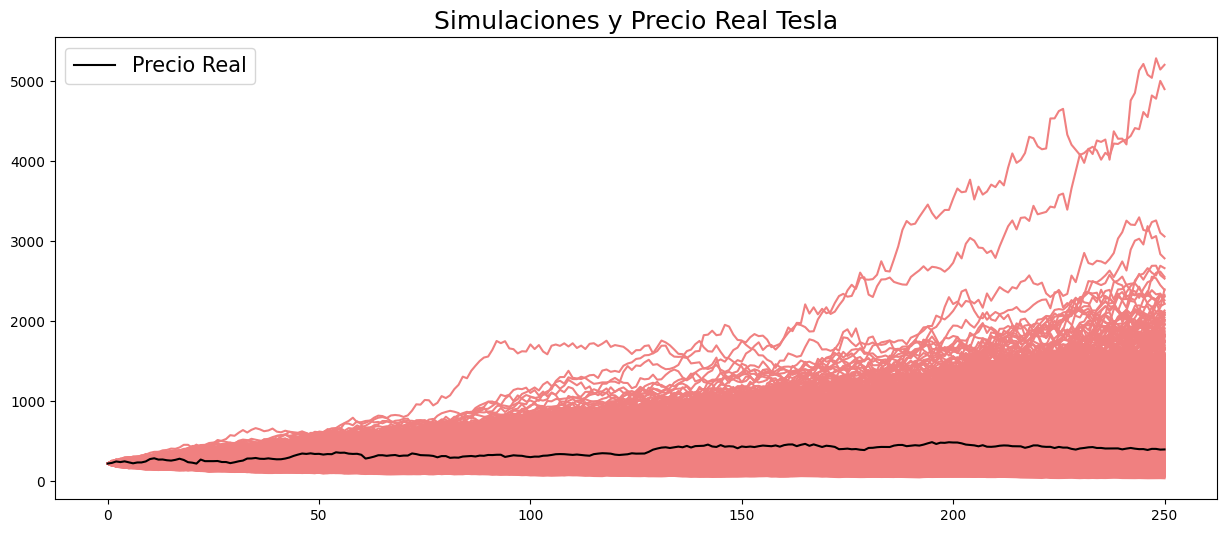

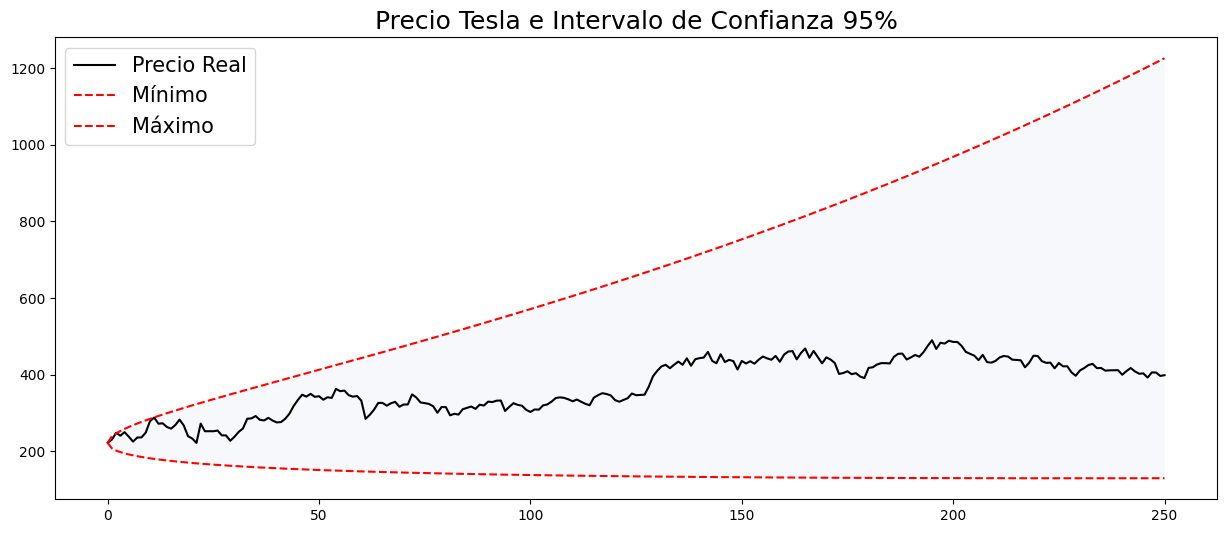

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


data = yf.download("TSLA", period="1y")
precios_TSLA = data[['Close']]
precios_TSLA.columns = ['TSLA']


rend_TSLA = precios_TSLA.pct_change().dropna()
lr_TSLA = np.log(rend_TSLA+1)

mu = lr_TSLA.mean().iloc[0]
sigma = lr_TSLA.std(ddof=1).iloc[0]

# Simulación de trayectorias
S_0 = precios_TSLA.iloc[0,0]
grid = np.arange(len(precios_TSLA))

plt.figure(figsize=(15,6))
for i in range(10_000):
    Browniano = np.append(0,stats.norm.rvs(0,1,size=len(grid)-1).cumsum())
    BGeometrico = S_0 * np.exp(mu * grid +sigma * Browniano)
    plt.plot(grid, BGeometrico, color="lightcoral")

plt.title("Simulaciones y Precio Real Tesla", fontsize=18)
plt.plot(grid, precios_TSLA['TSLA'].values, color="black", label="Precio Real")
plt.legend(loc="upper left", fontsize=15)

# Graficar unicamente los intervalos de confianza
z = stats.norm.ppf(0.975)
lower = np.e**(np.log(S_0) + mu*grid - z*sigma*(np.sqrt(grid)))
upper = np.e**(np.log(S_0) + mu*grid + z*sigma*(np.sqrt(grid)))

plt.figure(figsize=(15,6))
plt.plot(grid,precios_TSLA.values,color="black",label="Precio Real")
plt.plot(grid, lower, '--r', label="Mínimo")
plt.plot(grid, upper, '--r', label="Máximo")

plt.title("Precio Tesla e Intervalo de Confianza 95%", fontsize=18)
plt.legend(fontsize=15)
plt.gca().fill_between(grid, 
                       lower, upper, 
                       facecolor='lightsteelblue', 
                       alpha=0.1)

plt.show()